## Example of opening a OSTIA Icechunk v2 store for in cloud access 

#### Python environment

icechunk == 2.1.2

xarray == 2026.4.0

earthaccess == 0.18.0

zarr == 3.2.1

In [ ]:
#!pip install "icechunk==2.1.2"

In [1]:
!pip list | grep -E "icec|^xarray|earth|^zarr"

earthaccess                   0.18.0
icechunk                      2.1.2
xarray                        2026.4.0
zarr                          3.2.1


In [2]:
import icechunk
import xarray as xr
import earthaccess

### Setup and read the icechunk store in a UAT bucket

In [3]:
import os
import icechunk
import xarray as xr
import earthaccess

# --- 1. Fetch OPS Credentials for the Underlying Data Files ---
# Make sure we are pointing to Production (OPS) first
os.environ.pop("EARTHDATA_ENV", None)
earthaccess.login() # Logs into production URS
ops_creds = earthaccess.get_s3_credentials(daac="PODAAC")

# --- 2. Fetch UAT Credentials for the Icechunk VDS Repository ---
uat_auth = earthaccess.login(system=earthaccess.UAT)

# Get temporary credentials from the PODAAC UAT endpoint
uat_creds = uat_auth.get_s3_credentials(
    daac="PODAAC",
    endpoint="https://archive.podaac.uat.earthdata.nasa.gov/s3credentials"
)


# --- 3. Configure the Virtual Credentials for the Actual Data (OPS) ---
edl_virtual_creds = icechunk.s3_static_credentials(
    access_key_id=ops_creds["accessKeyId"],
    secret_access_key=ops_creds["secretAccessKey"],
    session_token=ops_creds["sessionToken"]
)

# Map the OPS protected bucket to the OPS credentials we fetched in step 1
auth_map = icechunk.containers_credentials({
    "s3://podaac-ops-cumulus-protected/": edl_virtual_creds
})

# --- 4. Configure Storage for Icechunk Metadata (UAT) ---
# Give the UAT public bucket the UAT credentials we fetched in step 2
storage = icechunk.s3_storage(
    bucket="podaac-uat-cumulus-public",
    #prefix="virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0_virtual_s3.icechunk/",
    prefix="virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.s3",
    access_key_id=uat_creds['accessKeyId'],
    secret_access_key=uat_creds['secretAccessKey'],
    session_token=uat_creds['sessionToken']
)

# --- 5. Open Repo and Load Data ---
# This merges both environments seamlessly
repo = icechunk.Repository.open(
    storage,
    authorize_virtual_chunk_access=auth_map
)

session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, consolidated=False)

print("Successfully loaded cross-environment dataset!")
print(ds)

Successfully loaded cross-environment dataset!
<xarray.Dataset> Size: 3TB
Dimensions:           (time: 3653, lat: 3600, lon: 7200)
Coordinates:
  * time              (time) datetime64[ns] 29kB 1989-12-31T12:00:00 ... 1999...
  * lat               (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon               (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
Data variables:
    analysed_sst      (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    analysis_error    (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    sea_ice_fraction  (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    mask              (time, lat, lon) float32 379GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
Attributes: (12/48)
    Conventions:                CF-1.4, ACDD-1.3
    title:                      Global SST & Sea Ice Analysis, L4 OSTIA, 0.05...
    summary:         

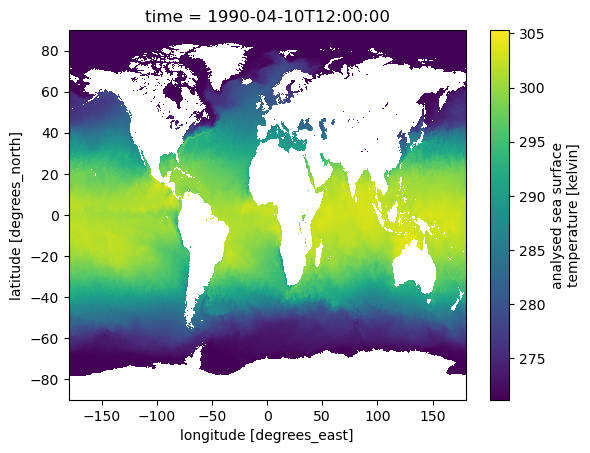

In [4]:
# Plot a single time step
ds["analysed_sst"].isel(time=100).plot()

In [5]:
# Do some spatial/temporal subsetting, averaging and resampling

# Define region 
# Gulf of Tehuantepec, MX
lat_min = 14.
lat_max = 15.
lon_min = -96.
lon_max = -95.

lat_range = (lat_min, lat_max)
lon_range = (lon_min, lon_max)

# for datasets that use 0-360 deg lon
lon_range_360 = (lon_min+360, lon_max+360)

# Define the time slice 
start_date = '1990-01-01'
#end_date = '1998-12-31'
end_date = '1990-12-31'
#end_date = '1994-12-31'
time_range =(start_date, end_date)

In [6]:
%%time
# A concise method to subset, resample, and average the xarray data all on one line
sst_resample = ds.analysed_sst.sel(lon=slice(*lon_range), lat=slice(*lat_range), time=slice(*time_range)
).mean(["lat", "lon"]).resample(time="1ME").mean().load()

CPU times: user 13.5 s, sys: 1.68 s, total: 15.2 s
Wall time: 16.9 s


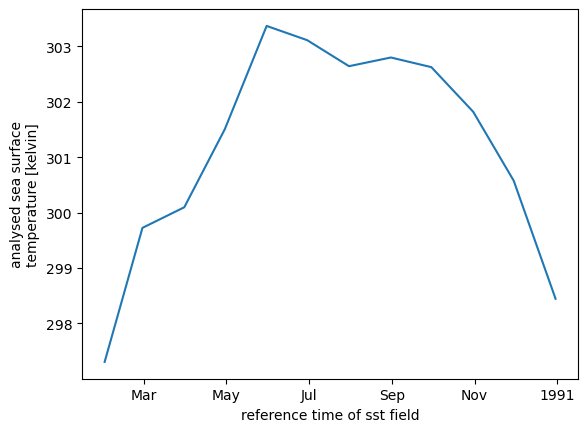

In [7]:
sst_resample.plot()